In [18]:
# Thư viện và cấu hình
import re
import time
from pathlib import Path
from collections import Counter

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, ConfusionMatrixDisplay
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
VOCAB_SIZE, EMBED, HIDDEN, BATCH, EPOCHS = 10000, 32, 32, 128, 3

def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

## 1. Dataset inspection và tokenization

Source: /kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv
Samples: 50000 | Classes: 2
Class distribution:
 sentiment
positive    25000
negative    25000
Name: count, dtype: int64
Duplicates: 418
Missing text: 0 | Missing labels: 0
Length (min/median/mean/max): 6 175.0 233.8 2482
Percentiles 50/75/90/95: [175 284 456 597]


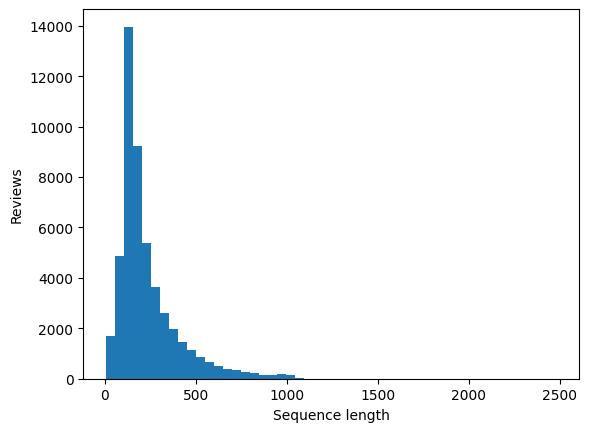

In [19]:
# IMDb 50K từ Kaggle
paths = [Path("IMDB Dataset.csv"), Path("/kaggle/input/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv")]
file = next((p for p in paths if p.exists()), None)
if file is None:
    file = Path(kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")) / "IMDB Dataset.csv"
df = pd.read_csv(file)
print("Source:", file)
print("Samples:", len(df), "| Classes:", df.sentiment.nunique())
print("Class distribution:\n", df.sentiment.value_counts())
print("Duplicates:", df.review.duplicated().sum())
print("Missing text:", df.review.isna().sum(), "| Missing labels:", df.sentiment.isna().sum())
lengths = df.review.fillna("").map(lambda x: len(tokenize(x))).to_numpy()
print("Length (min/median/mean/max):", lengths.min(), np.median(lengths), round(lengths.mean(), 1), lengths.max())
print("Percentiles 50/75/90/95:", np.percentile(lengths, [50, 75, 90, 95]).astype(int))
plt.hist(lengths, bins=50)
plt.xlabel("Sequence length")
plt.ylabel("Reviews")
plt.show()

In [20]:
# Train / validation / test: 80/10/10
train_df, other = train_test_split(df, test_size=0.2, stratify=df.sentiment, random_state=SEED)
val_df, test_df = train_test_split(other, test_size=0.5, stratify=other.sentiment, random_state=SEED)
train_text, val_text, test_text = [part.review.fillna("").tolist() for part in (train_df, val_df, test_df)]
y_train, y_val, y_test = [(part.sentiment == "positive").astype(int).to_numpy() for part in (train_df, val_df, test_df)]
train_tokens, val_tokens, test_tokens = [[tokenize(t) for t in texts] for texts in (train_text, val_text, test_text)]
vocab = {w: i + 2 for i, (w, _) in enumerate(Counter(w for ts in train_tokens for w in ts).most_common(VOCAB_SIZE - 2))}
print("Train/val/test:", len(y_train), len(y_val), len(y_test), "| Vocabulary:", len(vocab) + 2)

def loader(tokens, labels, max_length, shuffle=False):
    x = np.zeros((len(tokens), max_length), dtype=np.int64)
    for i, ts in enumerate(tokens):
        ids = [vocab.get(w, 1) for w in ts[:max_length]]
        x[i, :len(ids)] = ids
    data = TensorDataset(torch.tensor(x), torch.tensor(labels, dtype=torch.float32))
    return DataLoader(data, batch_size=BATCH, shuffle=shuffle)

def retained(max_length):
    return 100 * sum(min(len(ts), max_length) for ts in test_tokens) / sum(map(len, test_tokens))

Train/val/test: 40000 5000 5000 | Vocabulary: 10000


## 2. Simple RNN cell

In [21]:
import sys
import glob

path = glob.glob('/kaggle/input/datasets/tngdngnguynlee/rnn-cell/rnn_cell.py', recursive=True)[0]
sys.path.insert(0, path.rsplit('/', 1)[0])

from rnn_cell import SimpleRNNCell

In [22]:
# Kiểm tra RNN cell
from rnn_cell import SimpleRNNCell
cell = SimpleRNNCell(2, 2)
print(cell.forward(np.array([1., 0.]), np.array([0.5, 0.2])))

[0.03326873 0.15774976]


## 3. Baseline và RNN / LSTM / GRU

In [23]:
# Model
class Classifier(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab) + 2, EMBED, padding_idx=0)
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[kind](EMBED, HIDDEN, batch_first=True)
        self.fc = nn.Linear(HIDDEN, 1)

    def forward(self, x):
        out, _ = self.rnn(self.embedding(x))
        last = (x != 0).sum(dim=1).clamp(min=1) - 1
        return self.fc(out[torch.arange(len(x), device=x.device), last]).squeeze(1)

def metrics(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
    return dict(Accuracy=accuracy_score(y, pred), Precision=p, Recall=r, F1=f)

def predict(model, data):
    model.eval()
    scores = []
    with torch.no_grad():
        for x, _ in data:
            scores.extend(torch.sigmoid(model(x.to(DEVICE))).cpu().numpy())
    scores = np.array(scores)
    return (scores >= 0.5).astype(int), scores

def train(kind, max_length=100):
    torch.manual_seed(SEED)
    tr = loader(train_tokens, y_train, max_length, True)
    va = loader(val_tokens, y_val, max_length)
    te = loader(test_tokens, y_test, max_length)
    model = Classifier(kind).to(DEVICE)
    optim = torch.optim.Adam(model.parameters(), lr=0.002)
    loss_fn = nn.BCEWithLogitsLoss()
    history = []
    start = time.perf_counter()
    for epoch in range(EPOCHS):
        model.train()
        total = 0
        for x, y in tr:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optim.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optim.step()
            total += loss.item() * len(y)
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for x, y in va:
                val_loss += loss_fn(model(x.to(DEVICE)), y.to(DEVICE)).item() * len(y)
        history.append([epoch + 1, total / len(y_train), val_loss / len(y_val)])
    pred, prob = predict(model, te)
    result = dict(Model=kind, Max_length=max_length, Parameters=sum(p.numel() for p in model.parameters()),
                  Training_time=round(time.perf_counter() - start, 2), Epochs=EPOCHS,
                  Vocabulary=len(vocab) + 2, Tokens_retained=round(retained(max_length), 2), **metrics(y_test, pred))
    return model, pred, prob, pd.DataFrame(history, columns=["Epoch", "Train loss", "Validation loss"]), result

In [24]:
# TF-IDF + Logistic Regression
start = time.perf_counter()
vectorizer = TfidfVectorizer(max_features=VOCAB_SIZE)
a = vectorizer.fit_transform(train_text)
b = vectorizer.transform(test_text)
lr = LogisticRegression(max_iter=300).fit(a, y_train)
lr_pred = lr.predict(b)
lr_result = dict(Model="TF-IDF + LR", Max_length=0, Parameters=len(lr.coef_.ravel()) + 1,
                 Training_time=round(time.perf_counter() - start, 2), Epochs=0,
                 Vocabulary=len(vectorizer.vocabulary_), Tokens_retained=100, **metrics(y_test, lr_pred))
print(pd.DataFrame([lr_result]).round(3).to_string(index=False))

      Model  Max_length  Parameters  Training_time  Epochs  Vocabulary  Tokens_retained  Accuracy  Precision  Recall    F1
TF-IDF + LR           0       10001          10.35       0       10000              100     0.897        0.9   0.894 0.897


In [25]:
# RNN / LSTM / GRU
runs = {kind: train(kind) for kind in ["RNN", "LSTM", "GRU"]}
print(pd.DataFrame([lr_result] + [run[4] for run in runs.values()]).round(3).to_string(index=False))

      Model  Max_length  Parameters  Training_time  Epochs  Vocabulary  Tokens_retained  Accuracy  Precision  Recall    F1
TF-IDF + LR           0       10001          10.35       0       10000           100.00     0.897      0.900   0.894 0.897
        RNN         100      322145          24.92       3       10000            41.37     0.559      0.576   0.447 0.503
       LSTM         100      328481          29.17       3       10000            41.37     0.778      0.775   0.785 0.780
        GRU         100      326369          48.98       3       10000            41.37     0.814      0.864   0.745 0.800


## 4. Padding / truncation và sequence length

      Model  Max_length  Parameters  Training_time  Epochs  Vocabulary  Tokens_retained  Accuracy  Precision  Recall    F1
TF-IDF + LR           0       10001          10.35       0       10000           100.00     0.897      0.900   0.894 0.897
        RNN         100      322145          24.92       3       10000            41.37     0.559      0.576   0.447 0.503
       LSTM         100      328481          29.17       3       10000            41.37     0.778      0.775   0.785 0.780
        GRU         100      326369          48.98       3       10000            41.37     0.814      0.864   0.745 0.800
       LSTM          50      328481          17.31       3       10000            21.45     0.761      0.770   0.746 0.757
       LSTM         200      328481          73.61       3       10000            68.45     0.739      0.677   0.915 0.778
Tăng max_length có thể giữ thêm ngữ cảnh nhưng tăng thời gian và không bảo đảm cải thiện F1.


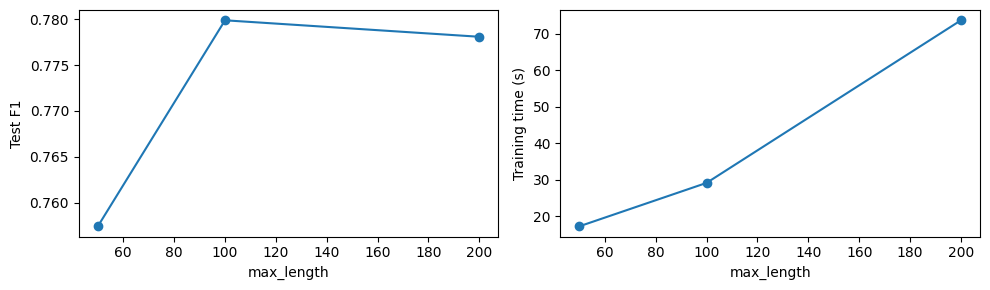

In [26]:
# max_length = 50 / 100 / 200
length_runs = {100: runs["LSTM"]}
for n in [50, 200]:
    length_runs[n] = train("LSTM", n)
results = pd.DataFrame([lr_result] + [run[4] for run in runs.values()] + [length_runs[n][4] for n in [50, 200]])
results.to_csv("results.csv", index=False)
print(results.round(3).to_string(index=False))
print("Tăng max_length có thể giữ thêm ngữ cảnh nhưng tăng thời gian và không bảo đảm cải thiện F1.")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ordered = [length_runs[n][4] for n in [50, 100, 200]]
ax[0].plot([50, 100, 200], [r["F1"] for r in ordered], marker="o")
ax[0].set(xlabel="max_length", ylabel="Test F1")
ax[1].plot([50, 100, 200], [r["Training_time"] for r in ordered], marker="o")
ax[1].set(xlabel="max_length", ylabel="Training time (s)")
plt.tight_layout()
plt.show()

## 5. Evaluation và learning curves

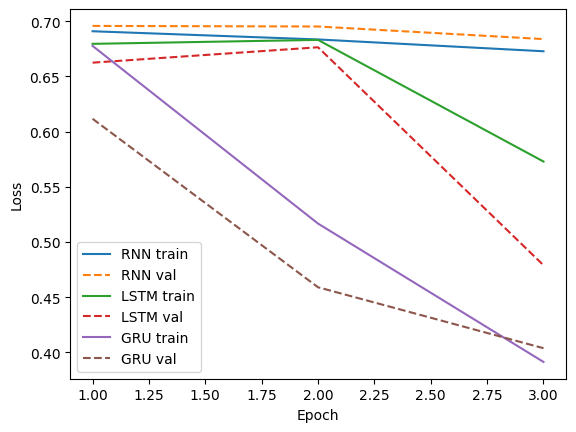

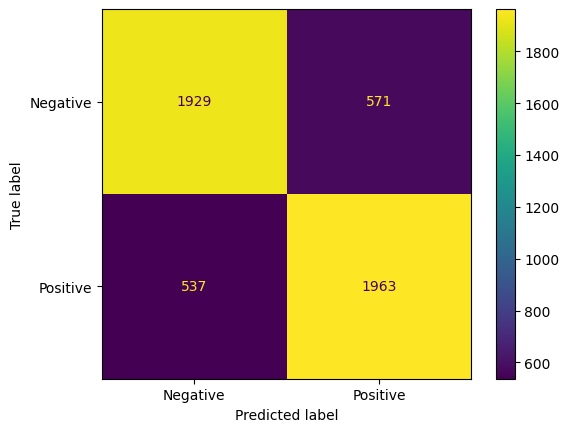

Overfitting: xem validation loss có tăng khi train loss tiếp tục giảm hay không.


In [27]:
# Learning curves
fig, ax = plt.subplots()
for kind in ["RNN", "LSTM", "GRU"]:
    h = runs[kind][3]
    ax.plot(h["Epoch"], h["Train loss"], label=f"{kind} train")
    ax.plot(h["Epoch"], h["Validation loss"], linestyle="--", label=f"{kind} val")
ax.set(xlabel="Epoch", ylabel="Loss")
ax.legend()
plt.savefig("learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, runs["LSTM"][1], display_labels=["Negative", "Positive"])
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
print("Overfitting: xem validation loss có tăng khi train loss tiếp tục giảm hay không.")

## 6. Long-range dependency

In [28]:
# Vị trí từ khóa
neutral = "The movie contains scenes with characters and conversations. " * 8
examples = []
for word in ["excellent", "terrible"]:
    for position, sentence in [("beginning", word + ". " + neutral),
                               ("middle", neutral[:len(neutral)//2] + " " + word + ". " + neutral[len(neutral)//2:]),
                               ("end", neutral + word + ".")]:
        examples.append((word, position, sentence))
model = runs["LSTM"][0]
encoded = loader([tokenize(t) for _, _, t in examples], [0] * len(examples), 100)
_, probs = predict(model, encoded)
print(pd.DataFrame([(w, pos, round(float(p), 3)) for (w, pos, _), p in zip(examples, probs)],
                   columns=["Keyword", "Position", "P(positive)"]).to_string(index=False))
print("Quan sát về vị trí từ khóa không tự chứng minh vanishing gradient.")

  Keyword  Position  P(positive)
excellent beginning        0.404
excellent    middle        0.313
excellent       end        0.303
 terrible beginning        0.124
 terrible    middle        0.153
 terrible       end        0.118
Quan sát về vị trí từ khóa không tự chứng minh vanishing gradient.


## 7. Application — sentiment classifier

In [29]:
# Review ngắn / dài / phủ định / tương phản
tests = {
    "short": "I loved this movie.",
    "long": "The film starts slowly with many conversations and ordinary events. " * 6 + "The ending was excellent.",
    "negation": "I did not like this movie.",
    "contrast": "I expected it to be terrible, but it was surprisingly good."
}
_, scores = predict(model, loader([tokenize(s) for s in tests.values()], [0] * 4, 100))
for (name, sentence), score in zip(tests.items(), scores):
    print(f"{name}: {'Positive' if score >= 0.5 else 'Negative'} | P(positive)={score:.3f} | {sentence[:90]}")
print("Chú ý tác động của not, but và vị trí từ đánh giá khi giải thích kết quả.")

short: Positive | P(positive)=0.707 | I loved this movie.
long: Positive | P(positive)=0.885 | The film starts slowly with many conversations and ordinary events. The film starts slowly
negation: Negative | P(positive)=0.286 | I did not like this movie.
contrast: Positive | P(positive)=0.524 | I expected it to be terrible, but it was surprisingly good.
Chú ý tác động của not, but và vị trí từ đánh giá khi giải thích kết quả.


## 8. Error analysis — 3 đúng và 3 sai

In [30]:
# Xuất ví dụ thực nghiệm
pred = runs["LSTM"][1]
correct = np.where(pred == y_test)[0][:3]
wrong = np.where(pred != y_test)[0][:3]

def hint(text):
    t = text.lower()
    if re.search(r"\b(not|never|no|n't)\b", t):
        return "Có phủ định; cần xem phạm vi và ngữ cảnh."
    if re.search(r"\b(but|however|although|though)\b", t):
        return "Có tương phản; cần xem đánh giá trước/sau liên từ."
    if len(tokenize(text)) > 100:
        return "Review dài; cần kiểm tra phần bị cắt ở 100 tokens."
    return "Cần đọc lại từ đánh giá và ngữ cảnh liên quan."

lines = ["# Error analysis — IMDb 50K (Kaggle) / LSTM", "", "Phân tích từ dự đoán thật của model với `max_length=100`.", "",
         "| Kết quả | Text (trích) | True | Predicted | Analysis |", "|---|---|---|---|---|"]
for label, indices in [("Correct", correct), ("Incorrect", wrong)]:
    for i in indices:
        excerpt = test_text[int(i)].replace("\n", " ").replace("|", "/")[:220]
        lines.append(f"| {label} | {excerpt}... | {'positive' if y_test[i] else 'negative'} | {'positive' if pred[i] else 'negative'} | {hint(test_text[int(i)])} |")
lines += ["", "## Nhận xét", "", "- Các dấu hiệu ở cột Analysis là giả thuyết, không phải nguyên nhân đã được chứng minh.",
          "- Cần đọc toàn bộ 6 review để phân biệt lỗi sequence, từ hiếm, nhãn mơ hồ và truncation.",
          "- Không thể kết luận nguyên nhân chỉ từ accuracy hoặc một prediction."]
from pathlib import Path
Path("error_analysis.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("Correct:", len(correct), "| Incorrect:", len(wrong))
print("Đã ghi error_analysis.md; cần tự kiểm tra, bổ sung nhận xét cho 6 review.")

Correct: 3 | Incorrect: 3
Đã ghi error_analysis.md; cần tự kiểm tra, bổ sung nhận xét cho 6 review.
